In [1]:
import sys
sys.path.append("../scripts")
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from config import TRAIN_CSV

train = pd.read_csv(TRAIN_CSV)
X_train = train.drop(columns=["Class"])
y_train = train["Class"]

/home/s2026aj05468/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/home/s2026aj05468/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
for c in [0.01, 0.1, 1, 10, 100]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=c, max_iter=1000)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")
    print(f"C={c}: mean accuracy {scores.mean():.4f} (+/- {scores.std():.4f})")

C=0.01: mean accuracy 0.9188 (+/- 0.0020)
C=0.1: mean accuracy 0.9234 (+/- 0.0025)
C=1: mean accuracy 0.9240 (+/- 0.0024)
C=10: mean accuracy 0.9251 (+/- 0.0026)
C=100: mean accuracy 0.9261 (+/- 0.0027)


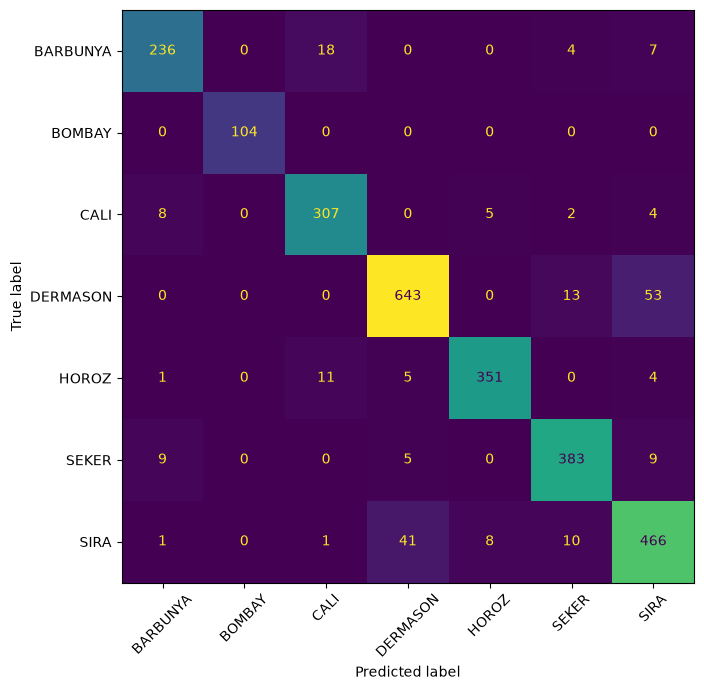

In [3]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from config import TEST_CSV, MODEL_DIR

test = pd.read_csv(TEST_CSV)
X_test = test.drop(columns=["Class"])
y_test = test["Class"]

model = joblib.load(MODEL_DIR / "logistic_regression.joblib")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

for d in [3, 5, 8, 12, 20, None]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    res = cross_validate(tree, X_train, y_train, cv=5, scoring="accuracy", return_train_score=True)
    print(f"max_depth={d}: train {res['train_score'].mean():.4f} | validation {res['test_score'].mean():.4f}")

max_depth=3: train 0.8017 | validation 0.7997
max_depth=5: train 0.9012 | validation 0.8877
max_depth=8: train 0.9488 | validation 0.9079
max_depth=12: train 0.9858 | validation 0.9014
max_depth=20: train 0.9991 | validation 0.8973
max_depth=None: train 1.0000 | validation 0.8972


In [5]:
for d in [6, 7, 8, 9, 10]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    res = cross_validate(tree, X_train, y_train, cv=5, scoring="accuracy", return_train_score=True)
    print(f"max_depth={d}: train {res['train_score'].mean():.4f} | validation {res['test_score'].mean():.4f}")

max_depth=6: train 0.9191 | validation 0.9008
max_depth=7: train 0.9352 | validation 0.9058
max_depth=8: train 0.9488 | validation 0.9079
max_depth=9: train 0.9610 | validation 0.9088
max_depth=10: train 0.9706 | validation 0.9057
